# MarketPulse - Entrega 3: Machine Learning

Primera capacidad inteligente: priorizar al cierre dos de ocho activos para revisión humana ante un posible movimiento absoluto relevante en la siguiente sesión. Se utiliza el Gold de la Entrega 2 sin repetir la adquisición.

**Reproducción:** instala `requirements.txt`, selecciona el kernel `.venv` y ejecuta todas las celdas. Si falta Gold, ejecuta primero el notebook 02. Todo el código está aquí. Se generan métricas, figuras, ejemplo de salida y el documento `docs/entregas/03_machine_learning.md`.

**Protocolo fijado antes del test:** evento = movimiento absoluto ajustado siguiente >=2 %; presupuesto = dos activos/día; train=2022, validación=2023, test=2024. Tres baselines y dos modelos, sin búsqueda de hiperparámetros. Selección por precisión@2 en validación. ML debe superar al mejor baseline en al menos un punto porcentual para justificar su complejidad. Test solo evalúa la decisión congelada.

## 1. Problema y utilidad

Un analista necesita decidir qué activos revisar con tiempo limitado. Se plantea **clasificación binaria con ranking** de movimiento absoluto futuro, no de dirección. El evento es un proxy de relevancia y no una etiqueta verdadera de anomalía. Esta evolución permite evaluar objetivamente si las señales de MarketPulse anticipan situaciones que merecen atención.

No se recomienda operar ni se mide rentabilidad. La utilidad primaria es cuántos eventos se encuentran con dos revisiones diarias; además se mide cobertura, discriminación y errores.

In [1]:
from pathlib import Path
import os
os.environ['OMP_NUM_THREADS'] = '2'
import hashlib
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'docs/entregas/02_datos_y_preparacion.md').exists()), None)
if ROOT is None:
    raise RuntimeError('Ejecuta desde la raíz del repositorio o notebooks.')
GOLD_PATH = ROOT / 'data/gold/marketpulse.csv'
OUT = ROOT / 'results/03_machine_learning'
OUT.mkdir(parents=True, exist_ok=True)
SEED, K = 42, 2
EVENT_THRESHOLD, MIN_ML_IMPROVEMENT = 0.02, 0.01
VAL_START, TEST_START = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-01-01')
BASELINES = ['volatilidad', 'movimiento_actual', 'volumen_relativo']
MODEL_NAMES = ['logistica', 'gradient_boosting']
FEATURES = ['daily_return', 'intraday_range_pct', 'relative_volume', 'volatility_20',
            'distance_to_high_20', 'distance_to_low_20']
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
ENV = {'python': platform.python_version(),
       **{p: version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'matplotlib']}}
display(pd.DataFrame([ENV]))

,python,pandas,numpy,scikit-learn,matplotlib
0,3.12.14,3.0.1,2.3.5,1.9.1,3.11.2


## 2. Datos de entrada y objetivo

Se usan seis variables relativas disponibles al cierre: rentabilidad, rango, volumen relativo, volatilidad previa y distancia a extremos previos. Se excluyen ticker/fecha como predictores y niveles absolutos de precio o volumen. Los indicadores ya están calculados en Gold sin usar futuro.

Objetivo por activo: `y_t = 1[abs(adj_close_(t+1)/adj_close_t - 1) >= 0.02]`. Se elimina la última observación sin siguiente cierre conocido. Se comprueba que los ocho activos comparten sesiones; no sustituye una auditoría externa del calendario.

In [2]:
if not GOLD_PATH.exists():
    raise FileNotFoundError('Falta Gold: ejecuta primero el notebook de Entrega 2.')
gold = pd.read_csv(GOLD_PATH, parse_dates=['date'], float_precision='round_trip')
gold = gold.sort_values(['symbol', 'date']).reset_index(drop=True)
quality02 = json.loads((GOLD_PATH.parent / 'quality_report.json').read_text())
assert sha256(GOLD_PATH) == quality02['gold_sha256'], 'Gold cambió respecto a Entrega 2.'
assert gold.symbol.nunique() == 8 and not gold.duplicated(['symbol', 'date']).any()
assert np.isfinite(gold[FEATURES + ['adj_close']]).all().all()
assert gold.date.min() >= pd.Timestamp('2022-01-01') and gold.date.max() < pd.Timestamp('2025-01-01')
assert len(set(gold.groupby('symbol')['date'].apply(lambda s: tuple(s)))) == 1
assert (gold.adj_close > 0).all()
data = gold.copy()
groups = data.groupby('symbol', sort=False)
data['label_date'] = groups['date'].shift(-1)
data['future_return'] = groups['adj_close'].shift(-1) / data.adj_close - 1
data = data.dropna(subset=['label_date', 'future_return']).copy()
data['future_abs_return'] = data.future_return.abs()
data['y'] = data.future_abs_return.ge(EVENT_THRESHOLD).astype(int)
assert (data.label_date > data.date).all()
assert not (set(FEATURES) & {'y', 'future_return', 'future_abs_return', 'label_date'})
print(f'Gold: {len(gold)} filas; supervisado: {len(data)}; sin objetivo: {len(gold)-len(data)}.')
display(data[['date', 'symbol', *FEATURES, 'label_date', 'y']].head(3))

Gold: 5856 filas; supervisado: 5848; sin objetivo: 8.


,date,symbol,daily_return,intraday_range_pct,relative_volume,volatility_20,distance_to_high_20,distance_to_low_20,label_date,y
0,2022-02-02,AAPL,0.007044,0.014502,0.812510,0.021199,-0.038811,0.136651,2022-02-03,0
1,2022-02-03,AAPL,-0.016720,0.023829,0.861539,0.021128,-0.040351,0.117647,2022-02-04,0
2,2022-02-04,AAPL,-0.001679,0.019839,0.796515,0.020604,-0.025795,0.115770,2022-02-07,0


### Validación temporal y controles de leakage

Todas las filas de una fecha permanecen juntas. Se purga la última sesión de train/validación si su etiqueta cae en el siguiente periodo. El escalador se ajusta solo con train. No se barajan filas; Gradient Boosting desactiva su early stopping interno para evitar una división aleatoria oculta.

Usar el histórico previo de otro periodo para indicadores es compatible con el uso diario. Las etiquetas nunca cruzan el límite de ajuste. Persisten los ajustes retrospectivos de Yahoo: esto no es una base point-in-time.

In [3]:
train = data.loc[(data.date < VAL_START) & (data.label_date < VAL_START)].copy()
val = data.loc[(data.date >= VAL_START) & (data.date < TEST_START)
               & (data.label_date < TEST_START)].copy()
test = data.loc[data.date >= TEST_START].copy()
assert train.label_date.max() < val.date.min()
assert val.label_date.max() < test.date.min()
assert set(train.date).isdisjoint(val.date) and set(val.date).isdisjoint(test.date)
assert all(frame.y.nunique() == 2 for frame in [train, val, test])
assert all(frame.groupby('date').size().eq(8).all() for frame in [train, val, test])
split_summary = pd.DataFrame([{
    'conjunto': name, 'filas': len(frame), 'sesiones': frame.date.nunique(),
    'inicio': str(frame.date.min().date()), 'fin': str(frame.date.max().date()),
    'ultima_etiqueta': str(frame.label_date.max().date()),
    'eventos': int(frame.y.sum()), 'prevalencia': float(frame.y.mean())}
    for name, frame in [('train', train), ('validacion', val), ('test', test)]]).set_index('conjunto')
purged = len(data) - len(train) - len(val) - len(test)
print('Filas purgadas en las fronteras:', purged)
display(split_summary)
split_summary.to_csv(OUT / 'particiones.csv')

Filas purgadas en las fronteras: 16


,filas,sesiones,inicio,fin,ultima_etiqueta,eventos,prevalencia
conjunto,,,,,,,
train,1832,229,2022-02-02,2022-12-29,2022-12-30,737,0.402293
validacion,1992,249,2023-01-03,2023-12-28,2023-12-29,390,0.195783
test,2008,251,2024-01-02,2024-12-30,2024-12-31,367,0.182769


## 3. Baselines y selección de modelos

Baselines sin ajuste: mayor volatilidad previa, mayor rentabilidad absoluta actual y mayor volumen relativo. Volatilidad es un control fuerte de persistencia del riesgo. Con selección uniforme aleatoria se espera una precisión igual a la prevalencia.

ML: logística regularizada con estandarización dentro de Pipeline (C=1, máximo 2000 iteraciones) y Gradient Boosting pequeño (100 iteraciones, tasa 0.05, 7 hojas, mínimo 30 filas/hoja, L2=1). Semilla 42. No hay búsqueda ni ajuste del evento o presupuesto tras ver resultados.

Se elige el mejor baseline y el mejor ML según P@2 en 2023, AP como desempate y orden estable si persiste. ML debe mejorar al baseline al menos un punto porcentual; de lo contrario se mantiene la regla sencilla.

In [4]:
def make_models():
    return {'logistica': make_pipeline(StandardScaler(), LogisticRegression(
                C=1.0, max_iter=2000, random_state=SEED)),
            'gradient_boosting': HistGradientBoostingClassifier(
                learning_rate=0.05, max_iter=100, max_leaf_nodes=7,
                min_samples_leaf=30, l2_regularization=1.0,
                early_stopping=False, random_state=SEED)}

def baseline_scores(frame):
    return {'volatilidad': frame.volatility_20.to_numpy(),
            'movimiento_actual': frame.daily_return.abs().to_numpy(),
            'volumen_relativo': frame.relative_volume.to_numpy()}

def rank_alerts(frame, scores):
    ranked = frame[['date', 'symbol', 'label_date', 'y', 'future_abs_return']].copy()
    ranked['score'] = np.asarray(scores)
    assert np.isfinite(ranked.score).all()
    ranked = ranked.sort_values(['date', 'score', 'symbol'], ascending=[True, False, True])
    ranked['rank'] = ranked.groupby('date').cumcount() + 1
    ranked['alert'] = ranked['rank'].le(K)
    return ranked.sort_values(['date', 'symbol']).reset_index(drop=True)

def evaluate(frame, scores):
    ranked = rank_alerts(frame, scores)
    tp = int((ranked.alert & ranked.y.eq(1)).sum())
    fp = int((ranked.alert & ranked.y.eq(0)).sum())
    fn = int((~ranked.alert & ranked.y.eq(1)).sum())
    precision, recall = tp/(tp+fp), tp/(tp+fn)
    return {'precision_at_2': precision, 'recall_at_2': recall,
            'f1_at_2': 2*precision*recall/(precision+recall) if precision+recall else 0.,
            'average_precision': float(average_precision_score(frame.y, scores)),
            'roc_auc': float(roc_auc_score(frame.y, scores)),
            'prevalencia': float(frame.y.mean()),
            'lift_vs_azar': precision/float(frame.y.mean()),
            'alertas': int(ranked.alert.sum()), 'tp': tp, 'fp': fp, 'fn': fn}, ranked

models_val = make_models()
val_scores = baseline_scores(val)
with threadpool_limits(limits=2):
    for name, model in models_val.items():
        model.fit(train[FEATURES], train.y)
        val_scores[name] = model.predict_proba(val[FEATURES])[:, 1]
val_metrics = pd.DataFrame({name: evaluate(val, scores)[0] for name, scores in val_scores.items()}).T
best_baseline = val_metrics.loc[BASELINES].sort_values(
    ['precision_at_2', 'average_precision'], ascending=False, kind='stable').index[0]
best_ml = val_metrics.loc[MODEL_NAMES].sort_values(
    ['precision_at_2', 'average_precision'], ascending=False, kind='stable').index[0]
val_improvement = float(val_metrics.loc[best_ml, 'precision_at_2'] - val_metrics.loc[best_baseline, 'precision_at_2'])
selected = best_ml if val_improvement >= MIN_ML_IMPROVEMENT else best_baseline
selection = {'best_baseline': best_baseline, 'best_ml': best_ml, 'selected': selected,
             'validation_improvement_ml': val_improvement,
             'minimum_required_improvement': MIN_ML_IMPROVEMENT, 'selection_uses_test': False}
print('Decisión congelada antes de test:', selection)
display(val_metrics.round(4))
val_metrics.to_csv(OUT / 'metricas_validacion.csv', index_label='metodo')
(OUT / 'seleccion_validacion.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')

Decisión congelada antes de test: {'best_baseline': 'volatilidad', 'best_ml': 'logistica', 'selected': 'volatilidad', 'validation_improvement_ml': -0.006024096385542188, 'minimum_required_improvement': 0.01, 'selection_uses_test': False}


,precision_at_2,recall_at_2,f1_at_2,average_precision,roc_auc,prevalencia,lift_vs_azar,alertas,tp,fp,fn
volatilidad,0.3213,0.4103,0.3604,0.3331,0.7031,0.1958,1.6410,498.0,160.0,338.0,230.0
movimiento_actual,0.2831,0.3615,0.3176,0.2657,0.5798,0.1958,1.4462,498.0,141.0,357.0,249.0
volumen_relativo,0.2209,0.2821,0.2477,0.2585,0.5525,0.1958,1.1282,498.0,110.0,388.0,280.0
logistica,0.3153,0.4026,0.3536,0.3511,0.7030,0.1958,1.6103,498.0,157.0,341.0,233.0
gradient_boosting,0.3052,0.3897,0.3423,0.3366,0.6822,0.1958,1.5590,498.0,152.0,346.0,238.0


217

## 4. Test y evaluación fuera de entrenamiento

Después de seleccionar en validación se reajustan ambos modelos con observaciones y etiquetas anteriores a 2024, sin cambiar parámetros. Se permite recuperar la última sesión de 2022, ya etiquetada antes de test. La tabla de todos los métodos en test es descriptiva; no cambia el elegido.

P@2 = proporción de alertas que anticipan evento; recall@2 = eventos capturados / eventos totales. AP y ROC-AUC miden ranking global, no calibración ni beneficio financiero. Siempre se revisan dos activos: es una cola de prioridad, no la afirmación de que existan dos anomalías cada día.

In [5]:
refit = data.loc[(data.date < TEST_START) & (data.label_date < TEST_START)].copy()
assert refit.label_date.max() < test.date.min()
models_final = make_models()
test_scores = baseline_scores(test)
with threadpool_limits(limits=2):
    for name, model in models_final.items():
        model.fit(refit[FEATURES], refit.y)
        test_scores[name] = model.predict_proba(test[FEATURES])[:, 1]
test_metrics = pd.DataFrame({name: evaluate(test, scores)[0] for name, scores in test_scores.items()}).T
rankings = {name: evaluate(test, scores)[1] for name, scores in test_scores.items()}
chosen, baseline_ranked = rankings[selected], rankings[best_baseline]
test_metrics.to_csv(OUT / 'metricas_test.csv', index_label='metodo')
print('Evaluación sin cambiar el elegido:', selected)
display(test_metrics.round(4))
cm = confusion_matrix(chosen.y, chosen.alert.astype(int), labels=[0, 1])
confusion = pd.DataFrame(cm, index=['sin_evento', 'evento'], columns=['sin_alerta', 'alerta'])
confusion.to_csv(OUT / 'matriz_confusion.csv')
display(confusion)

Evaluación sin cambiar el elegido: volatilidad


,precision_at_2,recall_at_2,f1_at_2,average_precision,roc_auc,prevalencia,lift_vs_azar,alertas,tp,fp,fn
volatilidad,0.3546,0.4850,0.4097,0.3520,0.7063,0.1828,1.9401,502.0,178.0,324.0,189.0
movimiento_actual,0.2749,0.3760,0.3176,0.2588,0.5886,0.1828,1.5041,502.0,138.0,364.0,229.0
volumen_relativo,0.2191,0.2997,0.2532,0.2246,0.5448,0.1828,1.1989,502.0,110.0,392.0,257.0
logistica,0.3466,0.4741,0.4005,0.3745,0.7227,0.1828,1.8965,502.0,174.0,328.0,193.0
gradient_boosting,0.3426,0.4687,0.3959,0.3822,0.7249,0.1828,1.8747,502.0,172.0,330.0,195.0


,sin_alerta,alerta
sin_evento,1317,324
evento,189,178


### Incertidumbre, errores y estabilidad

Las ocho filas del día comparten mercado. Se estima la diferencia de P@2 frente al baseline con bootstrap pareado de bloques contiguos de cinco sesiones, manteniendo juntos los activos del día: 2000 repeticiones, semilla 42. Es orientativo, con un solo año y un universo pequeño. Si el elegido es el baseline, su diferencia consigo mismo es cero; se publica además la del mejor ML de validación, sin cambiar la selección.

Se revisan concentración de alertas por activo, estabilidad por mes y cinco ejemplos de falsos positivos y de falsos negativos. Los FP consumen revisión sin evento >=2 %; los FN omiten eventos. Sin noticias no se atribuyen causas.

In [6]:
def daily_precision(ranked):
    return ranked.loc[ranked.alert].groupby('date').y.mean().sort_index()

def block_difference(left, right, repetitions=2000, block=5):
    delta = (daily_precision(left) - daily_precision(right)).to_numpy()
    rng = np.random.default_rng(SEED)
    n, samples = len(delta), []
    for _ in range(repetitions):
        starts = rng.integers(0, n-block+1, size=int(np.ceil(n/block)))
        indices = np.concatenate([np.arange(s, s+block) for s in starts])[:n]
        samples.append(delta[indices].mean())
    lo, hi = np.quantile(samples, [0.025, 0.975])
    return {'difference': float(delta.mean()), 'ci95_low': float(lo), 'ci95_high': float(hi),
            'block_sessions': block, 'repetitions': repetitions}

uncertainty = {'selected_vs_baseline': block_difference(chosen, baseline_ranked),
               'ml_vs_baseline': block_difference(rankings[best_ml], baseline_ranked)}
display(pd.DataFrame(uncertainty).T.round(4))
by_symbol = []
for symbol, frame in chosen.groupby('symbol'):
    tp, alerts, positives = int((frame.alert & frame.y.eq(1)).sum()), int(frame.alert.sum()), int(frame.y.sum())
    by_symbol.append({'symbol': symbol, 'eventos': positives, 'alertas': alerts,
        'tp': tp, 'fp': int((frame.alert & frame.y.eq(0)).sum()),
        'fn': int((~frame.alert & frame.y.eq(1)).sum()),
        'precision': tp/alerts if alerts else None, 'recall': tp/positives if positives else None})
by_symbol = pd.DataFrame(by_symbol).set_index('symbol')
by_symbol.to_csv(OUT / 'errores_por_activo.csv')
monthly = pd.DataFrame([{'mes': str(month),
    'precision_at_2': float(frame.loc[frame.alert, 'y'].mean()),
    'prevalencia': float(frame.y.mean()), 'alertas': int(frame.alert.sum())}
    for month, frame in chosen.groupby(chosen.date.dt.to_period('M'))]).set_index('mes')
monthly.to_csv(OUT / 'estabilidad_mensual.csv')
display(by_symbol.round(3))
display(monthly.round(3))
false_positives = chosen.loc[chosen.alert & chosen.y.eq(0)].sort_values(
    ['score', 'date', 'symbol'], ascending=[False, True, True]).head(5).assign(error='falso_positivo')
false_negatives = chosen.loc[~chosen.alert & chosen.y.eq(1)].sort_values(
    ['future_abs_return', 'date', 'symbol'], ascending=[False, True, True]).head(5).assign(error='falso_negativo')
errors = pd.concat([false_positives, false_negatives], ignore_index=True)
errors.to_csv(OUT / 'ejemplos_errores.csv', index=False)
display(errors[['date', 'symbol', 'score', 'rank', 'future_abs_return', 'error']])

,difference,ci95_low,ci95_high,block_sessions,repetitions
selected_vs_baseline,0.000,0.0000,0.0000,5.0,2000.0
ml_vs_baseline,-0.008,-0.0299,0.0159,5.0,2000.0


,eventos,alertas,tp,fp,fn,precision,recall
symbol,,,,,,,
AAPL,31,52,5,47,26,0.096,0.161
AMZN,54,72,18,54,36,0.250,0.333
GOOGL,41,29,4,25,37,0.138,0.098
META,62,109,35,74,27,0.321,0.565
MSFT,28,0,0,0,28,NaN,0.000
NVDA,121,240,116,124,5,0.483,0.959
QQQ,23,0,0,0,23,NaN,0.000
SPY,7,0,0,0,7,NaN,0.000


,precision_at_2,prevalencia,alertas
mes,,,
2024-01,0.262,0.137,42
2024-02,0.325,0.188,40
2024-03,0.350,0.181,40
2024-04,0.455,0.216,44
2024-05,0.295,0.131,44
2024-06,0.289,0.151,38
2024-07,0.477,0.267,44
2024-08,0.500,0.256,44
2024-09,0.300,0.175,40


,date,symbol,score,rank,future_abs_return,error
0,2024-08-15,NVDA,0.052819,1,0.014000,falso_positivo
1,2024-08-20,NVDA,0.052735,1,0.009823,falso_positivo
2,2024-08-13,NVDA,0.052417,1,0.016704,falso_positivo
3,2024-08-26,NVDA,0.051711,1,0.014550,falso_positivo
4,2024-08-08,NVDA,0.049745,1,0.002096,falso_positivo
5,2024-02-01,META,0.014288,3,0.203176,falso_negativo
6,2024-04-25,GOOGL,0.013838,4,0.102243,falso_negativo
7,2024-08-01,AMZN,0.015356,5,0.087847,falso_negativo
8,2024-02-01,AMZN,0.013855,4,0.078666,falso_negativo
9,2024-01-30,GOOGL,0.011103,5,0.075004,falso_negativo


In [7]:

concentrated = by_symbol.alertas.idxmax()
no_alert = by_symbol.index[by_symbol.alertas.eq(0)].tolist()
missed_without_alerts = int(by_symbol.loc[no_alert, 'fn'].sum())
monthly_min, monthly_max = monthly.precision_at_2.idxmin(), monthly.precision_at_2.idxmax()
worst_missed = false_negatives.iloc[0]
analysis_text = (
    f'{concentrated} concentra {int(by_symbol.loc[concentrated, "alertas"])} de '
    f'{int(chosen.alert.sum())} alertas ({by_symbol.loc[concentrated, "alertas"]/chosen.alert.sum():.1%}). '
    f'No reciben alertas {", ".join(no_alert) or "ningún activo"}; '
    f'en ellos se omiten {missed_without_alerts} eventos. Esto favorece la volatilidad estructural '
    'y limita la interpretación como detector de anomalías relativas a cada activo. '
    f'La P@2 mensual oscila entre {monthly.loc[monthly_min, "precision_at_2"]:.1%} '
    f'({monthly_min}) y {monthly.loc[monthly_max, "precision_at_2"]:.1%} ({monthly_max}). '
    f'El mayor FN mostrado es {worst_missed.symbol} el {worst_missed.date.date()}, '
    f'con movimiento posterior de {worst_missed.future_abs_return:.1%} y rango '
    f'{int(worst_missed["rank"])}: baja volatilidad previa no descarta un salto. '
    'Los FP de mayor score ilustran que alta volatilidad reciente no garantiza un evento '
    'en la sesión siguiente. No se atribuye el salto a una noticia no observada.')
display(Markdown('### Lectura de los errores\n\n' + analysis_text))


### Lectura de los errores

NVDA concentra 240 de 502 alertas (47.8%). No reciben alertas MSFT, QQQ, SPY; en ellos se omiten 58 eventos. Esto favorece la volatilidad estructural y limita la interpretación como detector de anomalías relativas a cada activo. La P@2 mensual oscila entre 26.2% (2024-01) y 50.0% (2024-08). El mayor FN mostrado es META el 2024-02-01, con movimiento posterior de 20.3% y rango 3: baja volatilidad previa no descarta un salto. Los FP de mayor score ilustran que alta volatilidad reciente no garantiza un evento en la sesión siguiente. No se atribuye el salto a una noticia no observada.

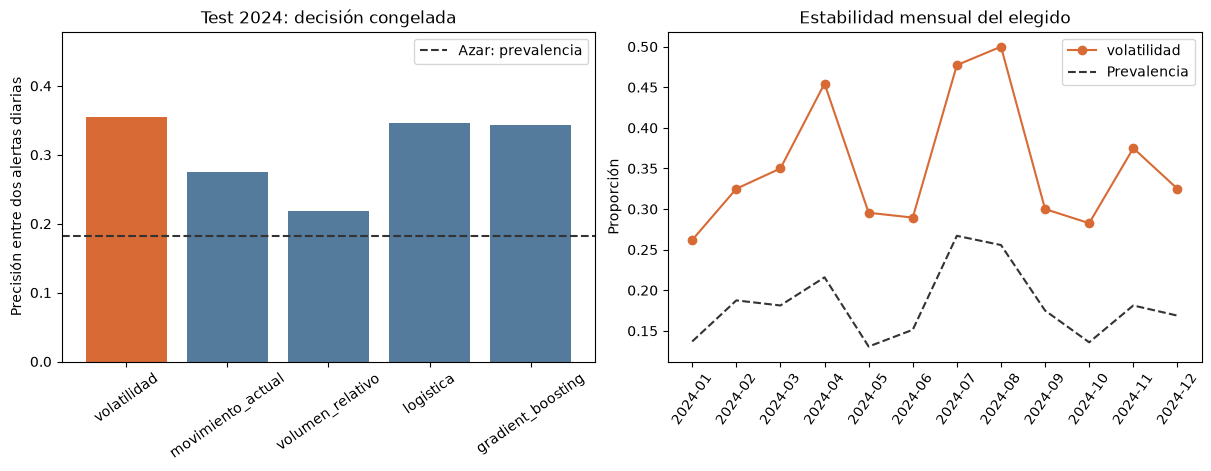

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
colors = ['#d76a35' if name == selected else '#547a9c' for name in test_metrics.index]
axes[0].bar(test_metrics.index, test_metrics.precision_at_2, color=colors)
axes[0].axhline(test.y.mean(), color='#333333', linestyle='--', label='Azar: prevalencia')
axes[0].set(ylabel='Precisión entre dos alertas diarias', title='Test 2024: decisión congelada')
axes[0].tick_params(axis='x', rotation=35)
axes[0].set_ylim(0, min(1, max(test_metrics.precision_at_2.max(), test.y.mean())*1.35))
axes[0].legend()
axes[1].plot(monthly.index, monthly.precision_at_2, marker='o', label=selected, color='#d76a35')
axes[1].plot(monthly.index, monthly.prevalencia, linestyle='--', label='Prevalencia', color='#333333')
axes[1].set(ylabel='Proporción', title='Estabilidad mensual del elegido')
axes[1].tick_params(axis='x', rotation=55)
axes[1].legend()
fig.savefig(OUT / 'comparacion_y_estabilidad.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Decisión y contrato del producto

La decisión depende solo de 2023. Puede ser adecuado mantener el baseline si ML no aporta una mejora suficiente. Esto constituye una conclusión válida: el alcance es un prototipo académico de cola de revisión, no un sistema validado para operar.

El frontal recibiría fecha, activo, score, rango diario, prioridad y contexto observado. El score se utiliza para ordenar y no se presenta como probabilidad calibrada. La escala del baseline depende de su indicador. El contexto no es una atribución causal del modelo. No se devuelve dirección ni órdenes de compraventa.

El ejemplo utiliza la última sesión del Gold (2024-12-31); es histórico, no una alerta actual. Se utiliza el mismo estimador que en test, sin reajustar con test ni desplegarlo.

In [9]:
latest = gold.loc[gold.date.eq(gold.date.max())].copy()
assert len(latest) == 8
if selected in MODEL_NAMES:
    with threadpool_limits(limits=2):
        latest_scores = models_final[selected].predict_proba(latest[FEATURES])[:, 1]
else:
    latest_scores = baseline_scores(latest)[selected]
latest['ranking_score'] = latest_scores
latest = latest.sort_values(['ranking_score', 'symbol'], ascending=[False, True]).reset_index(drop=True)
alerts = [{'symbol': row.symbol, 'ranking_score': float(row.ranking_score), 'rank': rank,
           'priority': rank <= K, 'context': {'relative_volume': float(row.relative_volume),
           'daily_return': float(row.daily_return), 'volatility_20': float(row.volatility_20)}}
          for rank, row in enumerate(latest.itertuples(), start=1)]
frontend = {'as_of': str(latest.date.max().date()), 'historical_example': True,
    'method': selected, 'requires_fitted_model': selected in MODEL_NAMES,
    'trained_label_through': str(refit.label_date.max().date()) if selected in MODEL_NAMES else None,
    'ml_comparison_labels_through': str(refit.label_date.max().date()),
    'horizon': 'next_market_session', 'event': 'absolute_adjusted_return_at_least_2pct',
    'daily_review_budget': K, 'score_is_calibrated_probability': False,
    'score_meaning': 'Higher scores rank earlier for human review; scale depends on method.',
    'context_is_causal_explanation': False,
    'cautions': ['Historical snapshot, not a live alert.', 'No direction or trading recommendation.',
                 'Retrospective adjusted prices.'], 'assets': alerts}
(OUT / 'ejemplo_salida_producto.json').write_text(json.dumps(frontend, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
display(pd.DataFrame(alerts)[['symbol', 'ranking_score', 'rank', 'priority']])

,symbol,ranking_score,rank,priority
0,GOOGL,0.023000,1,True
1,NVDA,0.020865,2,True
2,META,0.018877,3,False
3,AMZN,0.017689,4,False
4,QQQ,0.012790,5,False
5,MSFT,0.012674,6,False
6,AAPL,0.010262,7,False
7,SPY,0.009232,8,False


In [10]:
notebook_path = ROOT / 'notebooks/03_marketpulse_machine_learning.ipynb'
notebook_json = json.loads(notebook_path.read_text(encoding='utf-8'))
sources = [''.join(c['source']) if isinstance(c['source'], list) else c['source']
           for c in notebook_json['cells'] if c['cell_type'] == 'code']
run = {'gold_sha256': sha256(GOLD_PATH), 'gold_rows': len(gold),
    'pipeline_code_sha256': hashlib.sha256('\n'.join(sources).encode()).hexdigest(),
    'environment': ENV, 'seed': SEED, 'features': FEATURES,
    'event_threshold': EVENT_THRESHOLD, 'daily_budget': K,
    'train_validation_test_years': [2022, 2023, 2024], 'purged_rows': purged,
    'selection': selection, 'uncertainty': uncertainty,
    'validation': val_metrics.to_dict(orient='index'), 'test': test_metrics.to_dict(orient='index')}
(OUT / 'experimento.json').write_text(json.dumps(run, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')

def markdown_table(frame, digits=4):
    table = frame.reset_index()
    lines = ['| ' + ' | '.join(str(c) for c in table.columns) + ' |',
             '| ' + ' | '.join('---' for _ in table.columns) + ' |']
    for row in table.itertuples(index=False, name=None):
        values = [f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in row]
        lines.append('| ' + ' | '.join(values) + ' |')
    return '\n'.join(lines)

chosen_metrics, base_metrics = test_metrics.loc[selected], test_metrics.loc[best_baseline]
ci = uncertainty['ml_vs_baseline']
if selected in MODEL_NAMES:
    decision_text = (f'Se elige **{selected}**: en validación supera al mejor baseline ({best_baseline}) '
        f'en {val_improvement*100:.2f} puntos porcentuales de P@2, por encima del mínimo fijado de 1 punto.')
else:
    decision_text = (f'Se elige el baseline **{selected}**. El mejor ML de validación ({best_ml}) '
        f'cambia la P@2 en {val_improvement*100:+.2f} puntos porcentuales frente al baseline; '
        'no alcanza la mejora mínima fijada de 1 punto que justificaría más complejidad.')
error_counts = f'TP={int(chosen_metrics.tp)}, FP={int(chosen_metrics.fp)}, FN={int(chosen_metrics.fn)}'
selected_vs_base = float(chosen_metrics.precision_at_2-base_metrics.precision_at_2)
conclusion = (f'En test, el elegido consigue P@2={chosen_metrics.precision_at_2:.3f}, '
    f'recall@2={chosen_metrics.recall_at_2:.3f} y lift={chosen_metrics.lift_vs_azar:.2f} frente al azar. '
    f'La diferencia de P@2 frente al baseline es {selected_vs_base*100:+.2f} puntos. '
    f'El mejor ML de validación frente al baseline presenta un IC95% aproximado '
    f'[{ci["ci95_low"]*100:+.2f}, {ci["ci95_high"]*100:+.2f}] puntos. '
    'Son resultados del snapshot y no demuestran utilidad operativa general.')

In [11]:
report = f"# Entrega 3 - Machine Learning\n\n## 1. Qué problema resuelve el modelo\n\nMarketPulse ayuda a un analista a decidir qué activos revisar al cierre. La funcionalidad es clasificación binaria con ranking: anticipar un movimiento absoluto ajustado de al menos el 2 % en la siguiente sesión y priorizar dos de los ocho activos diarios. El evento futuro es un proxy de relevancia; no una etiqueta verdadera de anomalía ni una predicción de dirección. Concreta una primera evaluación del objetivo de la Entrega 2.\n\nEl valor esperado es encontrar más eventos con el mismo presupuesto de revisión humana. No se evalúa rentabilidad, ejecución, costes de compraventa ni una estrategia financiera.\n\n## 2. Datos de entrada y salida\n\nSe utiliza `data/gold/marketpulse.csv`, generado por [el notebook de Entrega 2](../../notebooks/02_marketpulse_datos_y_preparacion.ipynb). Gold contiene {len(gold)} filas y ocho activos. SHA-256: `{sha256(GOLD_PATH)}`. La adquisición y los entregables anteriores se conservan intactos.\n\nEntradas: `daily_return`, `intraday_range_pct`, `relative_volume`, `volatility_20`, `distance_to_high_20` y `distance_to_low_20`. Son variables relativas conocidas al cierre de t. Se excluyen ticker, fecha, niveles absolutos y cualquier etiqueta o estadística futura como predictores. La salida es un score para ordenar los activos y dos marcas de prioridad por día.\n\nObjetivo: `y_t = 1[abs(adj_close_(t+1)/adj_close_t - 1) >= 0.02]`, por activo. Se eliminan las ocho últimas filas sin siguiente cierre: quedan {len(data)} registros supervisados antes de purgar fronteras. El último día sí permite inferencia histórica, sin evaluar su acierto.\n\nSe comprueban claves únicas, valores finitos, precios positivos y sesiones comunes a todos los activos. Se purgan {purged} filas cuyas etiquetas cruzarían los cortes temporales. El escalado se ajusta dentro del Pipeline solo con entrenamiento. Los indicadores previos ya vienen de Gold. Persisten sesgos de selección y supervivencia, concentración tecnológica, mezcla de acciones con ETF y ajustes retrospectivos de Yahoo: no es una base point-in-time ni representa todo el mercado. No se recopilan nuevos datos personales.\n\n## 3. Baseline y selección de modelos\n\nSe comparan reglas sin entrenamiento: mayor volatilidad previa, mayor rentabilidad absoluta actual y mayor volumen relativo. Volatilidad controla la persistencia del riesgo y evita una referencia artificialmente débil. El azar tiene precisión esperada igual a la prevalencia.\n\nAlternativas: logística regularizada con StandardScaler dentro del Pipeline, C=1 y máximo 2000 iteraciones; HistGradientBoostingClassifier con 100 iteraciones, tasa 0.05, 7 hojas, mínimo 30 registros por hoja, L2=1 y early_stopping=False para no crear una validación aleatoria interna. Semilla 42. No se realiza búsqueda de hiperparámetros ni se reajusta el umbral del evento después de ver test.\n\nRegla fijada antes del test: escoger el mejor baseline y el mejor ML por P@2 en validación, usando AP y orden estable como desempates. El ML debe mejorar al baseline al menos un punto porcentual para justificar más complejidad.\n\n{decision_text}\n\nValidación 2023, ajustando con 2022:\n\n{markdown_table(val_metrics[['precision_at_2','recall_at_2','average_precision','roc_auc','lift_vs_azar']])}\n\n## 4. Validación y evaluación\n\nSeparación por fechas completas, conservando todos los activos del día en el mismo conjunto. Se eliminan etiquetas que caerían en el siguiente periodo. No se barajan filas. Tras seleccionar con 2023, se reajusta con observaciones y etiquetas anteriores a 2024; eso permite recuperar la última sesión de 2022, ya conocida antes de test. Los hiperparámetros no cambian.\n\n{markdown_table(split_summary)}\n\nMétrica primaria: precisión entre las dos alertas diarias. Recall@2 mide cobertura; AP y ROC-AUC, discriminación global. Lift es P@2 / prevalencia y no una rentabilidad. La selección uniforme aleatoria tiene precisión esperada igual a la prevalencia. No se usa accuracy porque puede ocultar errores con clases desbalanceadas. La política siempre propone dos activos: es una cola de revisión, no afirma que haya dos anomalías cada día.\n\nTest 2024 fuera de entrenamiento; la tabla de todos los métodos es descriptiva y no cambia la selección:\n\n{markdown_table(test_metrics[['precision_at_2','recall_at_2','average_precision','roc_auc','lift_vs_azar']])}\n\n{conclusion}\n\nMatriz de confusión del elegido: positivo predicho = estar en las dos prioridades diarias.\n\n{markdown_table(confusion, 0)}\n\nErrores del elegido: {error_counts}. Un falso positivo consume revisión sin un movimiento posterior >=2 %; un falso negativo omite un evento. No todo movimiento >2 % es una anomalía real y un movimiento menor podría seguir siendo interesante. En `ejemplos_errores.csv` se muestran cinco FP con mayor score y cinco FN con mayor magnitud futura. No se atribuyen a noticias o resultados empresariales sin haberlos observado.\n\n{markdown_table(by_symbol, 3)}\n\n{analysis_text} La estabilidad mensual se registra en `estabilidad_mensual.csv`. Los cortes no se utilizan para modificar el modelo.\n\n![Comparación y estabilidad](../../results/03_machine_learning/comparacion_y_estabilidad.png)\n\nEl intervalo de diferencias usa bootstrap pareado de bloques de cinco sesiones, 2000 repeticiones y semilla 42. Mantiene juntos los activos de un día y dependencia temporal local; no supone ocho series independientes. Si el elegido es el propio baseline, la diferencia consigo mismo es cero, por eso también se publica la del mejor ML de validación. Un único año, universo pequeño y umbral fijo no bastan para acreditar robustez. Se reconoce el cambio de prevalencia entre periodos. Quedan pendientes otros universos y periodos, validación walk-forward, etiquetas point-in-time y evaluación del coste de revisión.\n\n## 5. Decisión y uso en el producto\n\n{decision_text}\n\n{conclusion}\n\nEs suficiente para un prototipo académico de priorización con evaluación reproducible; no para decisiones financieras automáticas ni para garantizar detección general de anomalías. La mejora frente al baseline se distingue de la mejora frente al azar. No se proclama superioridad de ML si los resultados no la respaldan, ni se cambia de método al mirar test. No se despliega un modelo ni se construye el frontal.\n\nEl frontal consumiría `as_of`, `method`, `horizon`, `daily_review_budget` y una lista `assets` con `symbol`, `ranking_score`, `rank`, `priority` y contexto de volumen relativo, rentabilidad actual y volatilidad. Un score alto se revisa antes. No se presenta como probabilidad calibrada y su escala depende del método. El contexto describe señales observadas: no es una atribución causal del modelo. No se emite dirección, orden de compra/venta o retorno esperado.\n\n[Ejemplo JSON](../../results/03_machine_learning/ejemplo_salida_producto.json): sesión histórica {frontend['as_of']}, no una alerta actual. El baseline no necesita entrenamiento; los modelos comparados se ajustaron con etiquetas hasta {frontend['ml_comparison_labels_through']}, sin reajustar con test. El JSON indica explícitamente si el método requiere un estimador ajustado.\n\n**Reproducción:** instalar `requirements.txt`; abrir [el notebook de Entrega 3](../../notebooks/03_marketpulse_machine_learning.ipynb), seleccionar `.venv/Scripts/python.exe` y ejecutar todas las celdas. Si falta Gold, ejecutar primero el notebook 02. El experimento no necesita red una vez disponibles Gold y las dependencias. El notebook contiene todo el código y regenera este documento y las evidencias. Versiones, semillas, parámetros y huellas del Gold y del código se guardan en [experimento.json](../../results/03_machine_learning/experimento.json). Otra descarga puede cambiar los datos y requiere reevaluación.\n\nEvidencias en `results/03_machine_learning/`: particiones, métricas de validación y test, selección congelada, matriz de confusión, errores por activo, estabilidad mensual, ejemplos de errores, figura, JSON del producto y metadatos. No se guardan datasets masivos ni un modelo serializado.\n\nReferencias técnicas: [prevención de leakage con pipelines](https://scikit-learn.org/stable/common_pitfalls.html) y [HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).\n"
(ROOT / 'docs/entregas/03_machine_learning.md').write_text(report, encoding='utf-8')
display(Markdown('### Conclusión\n\n' + decision_text + '\n\n' + conclusion))
print('Documento y evidencias guardados en el repositorio local.')

### Conclusión

Se elige el baseline **volatilidad**. El mejor ML de validación (logistica) cambia la P@2 en -0.60 puntos porcentuales frente al baseline; no alcanza la mejora mínima fijada de 1 punto que justificaría más complejidad.

En test, el elegido consigue P@2=0.355, recall@2=0.485 y lift=1.94 frente al azar. La diferencia de P@2 frente al baseline es +0.00 puntos. El mejor ML de validación frente al baseline presenta un IC95% aproximado [-2.99, +1.59] puntos. Son resultados del snapshot y no demuestran utilidad operativa general.

Documento y evidencias guardados en el repositorio local.
